# 12 · 图像模型的架构

**这一组 notebook 的分工。**架构研究分三本：

| notebook | 问题 |
|---|---|
| **12（本篇）图像模型的架构** | 只换图像模型的结构、数据完全不变，准确率能提高多少？ |
| **12b 新架构** | 我们自己设计的、同时用图像和笔迹的结构（方向图 CNN、双流联合训练、交叉注意力、门控融合），能不能比 notebook 11 的"两个模型各自训练再融合"更好？ |
| **12c 蒸馏与浏览器代价** | 把最好的组合（集成或融合）压缩回上线的大小；所有候选在浏览器里的体积和延迟 |

**本篇的设计。**数据、增强、训练预算全部固定为 notebook 09 的方案 C（`recipe.py`），只换结构。比较五种：

| 结构 | 参考 | 思路 | 预期的优点 | 预期的缺点 |
|---|---|---|---|---|
| **cnn**（上线的） | [1] | 5 层 3×3 卷积 + 全局平均池化，10.7 万参数 | 简单、快 | — |
| **cnn_wide** | | 同样结构，通道数翻倍（41.5 万参数） | 容量更大 | 4 倍计算量，小数据上可能只是记得更多 |
| **resnet** | [25] | 3 个残差块 + BatchNorm（18 万参数） | 更深也好训练 | 28×28 的小图上深度未必有用 |
| **separable** | [26] | 前两层普通卷积，后面用深度可分离卷积（5.4 万参数） | 参数少一半 | 每层表达能力弱一些 |
| **convmixer** | [30] | 4×4 的块变成 7×7 个"词"，交替做空间混合和通道混合（13.5 万参数） | 和 Vision Transformer 同类的"块 + 混合"思路，但对小数据友好 | 第一层就把 4×4 的细节压成一个向量 |

每个结构训练两个种子。上线的 `cnn` 直接用 notebook 09 的两个方案 C 模型，不重新训练。

**还要回答的一个问题：**notebook 11 的融合把错误减少了约 40%。如果图像模型本身变强了，融合的收益还剩多少？第 5 节把每个结构都和 notebook 11 的轨迹模型融合一次。

**关于训练时间。**这台电脑只有 CPU，TensorFlow 的深度可分离卷积在 CPU 上特别慢，所以 `separable` 的前两层用普通卷积，`convmixer` 用 4×4 的块。表里会报告每个结构的训练时间，但真正关心的是**浏览器里的推理时间**，在 12c 测。

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from fingermath import archs, evaluate, models, recipe

REAL = Path('../cache/real'); RESULTS = Path('../results'); MODEL_DIR = Path('../cache/models')
SEEDS = recipe.SEEDS
plt.rcParams['figure.dpi'] = 110

meta, x_real = recipe.real_meta()
y = meta.label.to_numpy()
SPLITS = recipe.eval_splits(meta)
sources = recipe.sources_c(meta, recipe.strokes())
for x_, y_, _, frac in sources:
    print(x_.shape, f'{frac:.0%} of every batch')

(60000, 28, 28) 40% of every batch
(60000, 28, 28) 40% of every batch
(29990, 28, 28) 20% of every batch


## 1. 训练

模型存在 `cache/models/arch12_<结构>_s<种子>.keras`，再次运行时直接读取。

In [2]:
def model_path(name, seed):
    return MODEL_DIR / (f'real09_C_s{seed}.keras' if name == 'cnn' else f'arch12_{name}_s{seed}.keras')

def train_one(name, seed):
    path = model_path(name, seed)
    if path.exists():
        return keras.models.load_model(path), None
    keras.utils.set_random_seed(seed)
    ds = models.make_train_ds(sources, batch=recipe.BATCH, seed=seed).map(lambda a, b: (a, tf.one_hot(b, 10)))
    t0 = time.time()
    m = recipe.compile_and_fit(archs.BUILDERS[name](), ds, seed)
    m.save(path)
    return m, time.time() - t0

trained, P, rows = {}, {}, []
for name in archs.BUILDERS:
    for seed in SEEDS:
        m, secs = train_one(name, seed)
        trained[(name, seed)] = m
        P[(name, seed)] = m.predict(x_real[..., None], batch_size=2048, verbose=0)
        r = {'arch': name, 'seed': seed, 'params': m.count_params(), 'train min': None if secs is None else round(secs / 60, 1)}
        r.update({k: 100 * float((P[(name, seed)][idx].argmax(1) == y[idx]).mean()) for k, idx in SPLITS.items()})
        rows.append(r); print(name, seed, {k: round(v, 2) for k, v in r.items() if isinstance(v, float)})
runs = pd.DataFrame(rows)
np.savez_compressed(REAL / 'probs12.npz', **{f'{a}_{s}': p for (a, s), p in P.items()})

cnn 42 {'val: pen': 99.6, 'val: finger': 98.91, 'test: pen': 98.4, 'test: finger': 98.84}


cnn 43 {'val: pen': 99.53, 'val: finger': 98.65, 'test: pen': 97.94, 'test: finger': 98.72}


C:\Projects\Math-Run\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


cnn_wide 42 {'train min': 51.6, 'val: pen': 99.6, 'val: finger': 99.12, 'test: pen': 98.14, 'test: finger': 99.18}


cnn_wide 43 {'train min': 61.8, 'val: pen': 99.4, 'val: finger': 99.12, 'test: pen': 98.08, 'test: finger': 99.13}


...

resnet 43 {'train min': 43.5, 'val: pen': 99.47, 'val: finger': 99.44, 'test: pen': 98.28, 'test: finger': 99.32}


separable 42 {'train min': 20.8, 'val: pen': 99.47, 'val: finger': 99.12, 'test: pen': 98.08, 'test: finger': 99.03}


separable 43 {'train min': 20.1, 'val: pen': 99.53, 'val: finger': 99.17, 'test: pen': 98.28, 'test: finger': 99.02}


convmixer 42 {'train min': 30.4, 'val: pen': 99.53, 'val: finger': 98.83, 'test: pen': 98.11, 'test: finger': 98.75}


convmixer 43 {'train min': 33.4, 'val: pen': 99.53, 'val: finger': 98.84, 'test: pen': 97.97, 'test: finger': 98.83}


## 2. 结果

单个模型的准确率（两个种子的平均）。`seed spread` 是两个种子之间的最大差距：两个结构的差距如果小于它，就不能说谁更好。

In [3]:
cols = list(SPLITS)
mean = runs.groupby('arch', sort=False)[cols].mean()
mean['val mean'] = mean[['val: pen', 'val: finger']].mean(axis=1)
mean['seed spread (test, max)'] = runs.groupby('arch', sort=False)[['test: pen', 'test: finger']].agg(lambda v: v.max() - v.min()).max(axis=1)
mean.insert(0, 'params', runs.groupby('arch', sort=False).params.first())

def keras_ms(m):
    f = tf.function(lambda t: m(t, training=False)); one = x_real[:1, ..., None]; f(one)
    ts = []
    for _ in range(200):
        t0 = time.perf_counter(); f(one).numpy(); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts)
mean['ms / digit (Python)'] = [keras_ms(trained[(a, SEEDS[0])]) for a in mean.index]
mean.round(2)

,params,val: pen,val: finger,test: pen,test: finger,val mean,"seed spread (test, max)",ms / digit (Python)
arch,,,,,,,,
cnn,106730,99.57,98.78,98.17,98.78,99.17,0.46,4.04
cnn_wide,415498,99.50,99.12,98.11,99.15,99.31,0.06,5.59
resnet,181930,99.53,99.41,98.26,99.29,99.47,0.06,6.47
separable,53514,99.50,99.15,98.18,99.03,99.32,0.20,3.91
convmixer,136778,99.53,98.84,98.04,98.79,99.18,0.14,6.06


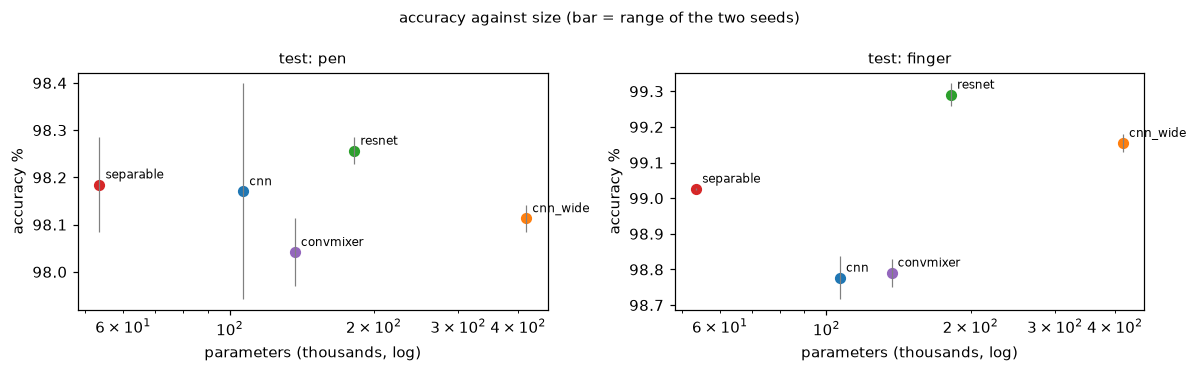

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, k in zip(axes, ['test: pen', 'test: finger']):
    for a in mean.index:
        v = runs[runs.arch == a][k]
        ax.scatter(mean.params[a] / 1000, v.mean(), s=40); ax.errorbar(mean.params[a] / 1000, v.mean(), yerr=(v.max() - v.min()) / 2, color='gray', lw=0.8)
        ax.annotate(a, (mean.params[a] / 1000, v.mean()), fontsize=8, xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('log'); ax.set_xlabel('parameters (thousands, log)'); ax.set_ylabel('accuracy %'); ax.set_title(k, fontsize=10)
plt.suptitle('accuracy against size (bar = range of the two seeds)', fontsize=10); plt.tight_layout(); plt.show()

## 3. 集成：几个模型一起投票

把多个模型的概率平均（深度集成 [27]）。三种情况：

- **同结构两个种子**：只差随机初始化；
- **不同结构**：五种结构各取种子 42；
- **全部 10 个模型**。

集成通常会提高准确率，但上线时要跑好几个模型。12c 会试着把集成"蒸馏"回一个小模型 [23]。

In [5]:
def acc(p, idx):
    return 100 * float((p[idx].argmax(1) == y[idx]).mean())

ens = {}
for a in archs.BUILDERS:
    ens[f'{a} x2 seeds'] = np.mean([P[(a, s)] for s in SEEDS], axis=0)
ens['5 archs (seed 42)'] = np.mean([P[(a, 42)] for a in archs.BUILDERS], axis=0)
ens['all 10'] = np.mean(list(P.values()), axis=0)
ens_table = pd.DataFrame({k: {s: acc(p, idx) for s, idx in SPLITS.items()} for k, p in ens.items()}).T
ens_table['val mean'] = ens_table[['val: pen', 'val: finger']].mean(axis=1)
ens_table.round(2)

,val: pen,val: finger,test: pen,test: finger,val mean
cnn x2 seeds,99.60,98.88,98.26,98.80,99.24
cnn_wide x2 seeds,99.53,99.12,98.11,99.23,99.33
resnet x2 seeds,99.60,99.37,98.17,99.30,99.49
separable x2 seeds,99.47,99.22,98.23,99.11,99.34
convmixer x2 seeds,99.53,98.84,98.03,98.88,99.19
5 archs (seed 42),99.53,99.31,98.31,99.23,99.42
all 10,99.53,99.29,98.28,99.24,99.41


## 4. 每个数字（测试集，两个种子平均）

In [6]:
def per_digit(p, idx):
    pred = p[idx].argmax(1)
    return [100 * (pred[y[idx] == c] == c).mean() for c in range(10)]

tabs = {}
for k in ['test: pen', 'test: finger']:
    for a in archs.BUILDERS:
        tabs[(k.split(': ')[1], a)] = np.mean([per_digit(P[(a, s)], SPLITS[k]) for s in SEEDS], axis=0)
digit_table = pd.DataFrame(tabs).round(1); digit_table.index.name = 'digit'
digit_table

pen                                     finger                  \
         cnn cnn_wide resnet separable convmixer    cnn cnn_wide resnet   
digit                                                                     
0      100.0    100.0  100.0     100.0     100.0   99.8     99.8   99.8   
1       98.6     98.6   98.5      97.9      98.4   97.9     98.5   98.8   
2       99.3     99.5   99.6      99.6      99.3   98.9     99.4   99.5   
3       98.8     98.5   99.1      99.0      98.5   98.4     99.3   99.6   
4       93.4     93.1   93.4      93.0      93.4   98.7     99.1   98.5   
5       99.6     99.3   98.5      99.1      98.4   99.3     99.3   99.5   
6       99.1     99.3   99.7      99.6      99.3   99.5     99.5   99.4   
7       96.4     96.0   97.1      97.0      95.9   98.9     99.1   99.4   
8       99.7    100.0  100.0     100.0      99.4   97.0     98.2   99.0   
9       97.0     97.2   96.9      97.0      98.2   99.4     99.4   99.4   

                           
      separable convmixer  
digit                      
0          99.8      99.9  
1          98.6      98.6  
2          99.3      99.4  
3          99.1      99.2  
4          98.2      95.1  
5          99.4      99.3  
6          99.2      99.1  
7          99.1      99.5  
8          98.1      98.7  
9          99.4      99.1

## 5. 和轨迹模型融合后还剩多少差别

每个结构都和 notebook 11 选中的轨迹模型（`cnn1d + templates`）融合。融合权重 $w$ 对每个结构**分别**在验证集上选，种子一一配对，和 notebook 11 的做法相同。

In [7]:
r11 = json.loads((RESULTS / '11_trajectory_and_fusion.json').read_text(encoding='utf-8'))
traj_name = r11['trajectory_chosen'].replace(' + ', '_')
X = None
PT = {}
for s in SEEDS:
    tm = keras.models.load_model(MODEL_DIR / f'traj11_{traj_name}_s{s}.keras')
    if X is None:
        from fingermath import trajectory
        from multiprocessing import Pool
        st = recipe.strokes()
        k_corr = np.flatnonzero(meta.source == 'corr')
        for a_, i in zip(trajectory.corr_strokes_in_order(Path('../cache/raw/corr')), k_corr):
            st[i] = a_
        with Pool() as pool:
            X = np.stack(pool.map(trajectory.encode, st, chunksize=200))
    PT[s] = tm.predict(X, batch_size=2048, verbose=0)

def fuse(p_img, p_traj, w):
    z = w * np.log(p_img + 1e-7) + (1 - w) * np.log(p_traj + 1e-7)
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

WS = np.round(np.arange(0, 1.0001, 0.05), 2)
fus = []
for a in archs.BUILDERS:
    val = [np.mean([np.mean([acc(fuse(P[(a, s)], PT[s], w), SPLITS[k]) for s in SEEDS]) for k in ['val: pen', 'val: finger']]) for w in WS]
    w = float(WS[int(np.argmax(val))])
    r = {'arch': a, 'w': w}
    for k in ['test: pen', 'test: finger']:
        img = np.mean([acc(P[(a, s)], SPLITS[k]) for s in SEEDS])
        f = np.mean([acc(fuse(P[(a, s)], PT[s], w), SPLITS[k]) for s in SEEDS])
        r[f'{k} image'] = img; r[f'{k} fused'] = f; r[f'{k} error cut %'] = 100 * (1 - (100 - f) / (100 - img))
    fus.append(r)
fus = pd.DataFrame(fus).set_index('arch')
fus.round(2)

,w,test: pen image,test: pen fused,test: pen error cut %,test: finger image,test: finger fused,test: finger error cut %
arch,,,,,,,
cnn,0.55,98.17,99.00,45.31,98.78,99.23,36.73
cnn_wide,0.60,98.11,98.97,45.45,99.15,99.35,22.78
resnet,0.65,98.26,98.81,31.97,99.29,99.51,31.16
separable,0.60,98.18,98.99,44.09,99.03,99.44,42.49
convmixer,0.50,98.04,99.00,48.91,98.79,99.33,44.54


## 6. 保存

In [8]:
out = {'runs': runs.to_dict(orient='records'), 'mean': mean.round(3).to_dict(orient='index'),
       'ensembles': ens_table.round(3).to_dict(orient='index'),
       'per_digit_test_percent': {f'{a} | {b}': v.tolist() for (a, b), v in digit_table.items()},
       'fusion_with_trajectory': fus.round(3).to_dict(orient='index'),
       'budget': dict(epochs=recipe.EPOCHS, steps=recipe.STEPS, batch=recipe.BATCH, smoothing=recipe.SMOOTHING), 'seeds': SEEDS}
(RESULTS / '12_image_architectures.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved results/12_image_architectures.json and cache/real/probs12.npz')

saved results/12_image_architectures.json and cache/real/probs12.npz


## 7. 结论

**1. 在手指上，换结构确实有用；在触控笔上几乎没用。**（两个种子平均）

| 结构 | 参数 | 触控笔 | 手指 | 手指错误减少 |
|---|---|---|---|---|
| cnn（上线的） | 10.7 万 | 98.17% | 98.78% | — |
| **resnet** | 18.2 万 | 98.26% | **99.29%** | **42%** |
| cnn_wide | 41.5 万 | 98.11% | 99.15% | 30% |
| **separable** | **5.4 万** | 98.18% | 99.03% | 20% |
| convmixer | 13.7 万 | 98.04% | 98.79% | 0% |

- 手指测试集有 177 人、1.4 万个样本，0.2 个百分点以上的差别就可信（两个种子之间相差 ≤ 0.06）。**残差网络最好**，错误减少 42%，只比上线的模型大 70%。
- **深度可分离卷积用一半的参数**（5.4 万）也比上线的模型好（错误少 20%），是"更小又更准"的选项。
- 加宽 4 倍不如加残差：容量本身不是瓶颈，BatchNorm 和残差带来的更好的优化（以及更平滑的特征）才是。
- ConvMixer 和上线的 CNN 一样：第一层就把 4×4 的细节压成一个向量，对这种细笔画的小图不利。
- **触控笔上所有结构都在 98.0–98.3%**。notebook 10 已经说明原因：触控笔的错误大半来自一位固定写法的书写者（`pd-b13` 的 4，所有结构都只有约 93%），换结构解决不了，只有笔迹（11、12b）或个性化（14）能解决。触控笔测试集只有 14 人，上线的 cnn 两个种子之间就差 0.46 个百分点，所以这里的小差别不可信。

**2. 集成帮助不大。**同一结构两个种子平均，或五种结构一起平均，最多再提高约 0.05 个百分点（手指）；"全部 10 个模型"（99.24%）还不如单个 resnet（99.29%）。说明 resnet 已经吃掉了集成能带来的大部分好处。这对 12c 的"集成后蒸馏"不太乐观：老师并不比最好的单个学生强多少。

**3. 更好的图像模型 + 轨迹模型 = 目前最好的结果。**和 notebook 11 的轨迹模型融合后：

| 图像模型 | 融合后：触控笔 | 融合后：手指 |
|---|---|---|
| cnn（11 的晚期融合） | 99.00% | 99.23% |
| **resnet** | 98.81% | **99.51%** |
| separable | 98.99% | 99.44% |

图像模型变强后，融合仍然能再减少 22–45% 的错误，两者的收益基本是叠加的。**resnet + 轨迹**在手指上达到 99.51%，是到目前为止所有方案里最高的；触控笔上 separable + 轨迹（98.99%）和 cnn + 轨迹（99.00%）更好，但如上所述触控笔的差别不太可信。按验证集（两个设备平均）排名，resnet + 轨迹也是第一。

**4. 速度。**Python 里单个样本：separable 3.9 ms，cnn 4.0 ms，resnet 6.5 ms。浏览器（WASM）里的实际延迟在 12c 测。

**对后续的影响。**
- 12c 的图像老师按验证集选出 resnet 和 separable（各两个种子）。
- 上线候选里应加入"resnet + 轨迹"和"separable + 轨迹"的晚期融合；12c 测完浏览器延迟后，在准确率、大小和速度之间做最终选择。
- 一个值得以后做的组合：把 12b 的 ink_glance 的图像部分换成残差结构。